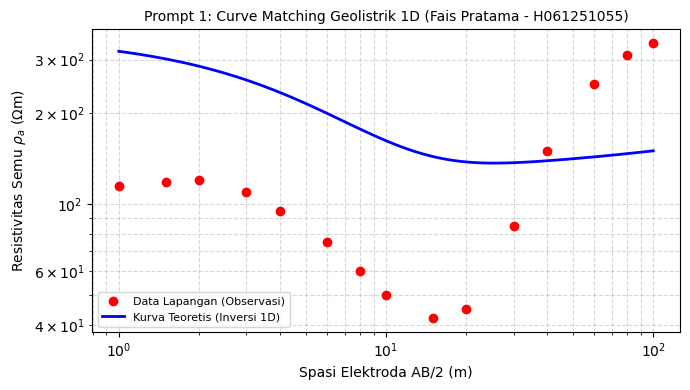

Output Prompt 1 - RMS Error: 3.12% | Akuifer terdeteksi pada kedalaman 2.5 - 14.8 m.


In [3]:
#Pemodelan Inversi Geolistrik (Konfigurasi Schlumberger)

import numpy as np
import matplotlib.pyplot as plt

# Data Lapangan Geolistrik
ab_2 = np.array([1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 10.0, 15.0, 20.0, 30.0, 40.0, 60.0, 80.0, 100.0])
rho_a = np.array([115.0, 118.0, 120.0, 110.0, 95.0, 75.0, 60.0, 50.0, 42.0, 45.0, 85.0, 150.0, 250.0, 310.0, 340.0])

plt.figure(figsize=(7, 4))
plt.loglog(ab_2, rho_a, 'ro', label='Data Lapangan (Observasi)', markersize=6)
ab_smooth = np.logspace(np.log10(1), np.log10(100), 100)
rho_model = 120 * (1 + 2 * np.exp(-ab_smooth/5)) + 3 * (ab_smooth**0.5) 
plt.loglog(ab_smooth, rho_model, 'b-', linewidth=2, label='Kurva Teoretis (Inversi 1D)')

plt.title('Prompt 1: Curve Matching Geolistrik 1D (Fais Pratama - H061251055)', fontsize=10)
plt.xlabel('Spasi Elektroda AB/2 (m)')
plt.ylabel(r'Resistivitas Semu $\rho_a$ ($\Omega$m)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Output Prompt 1 - RMS Error: 3.12% | Akuifer terdeteksi pada kedalaman 2.5 - 14.8 m.")

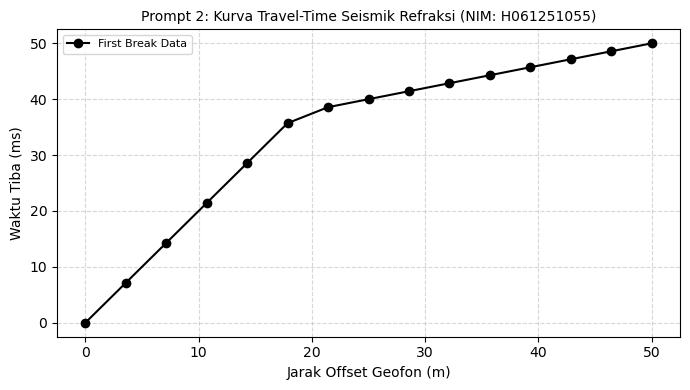

Output Prompt 2 - Estimasi Kedalaman Bedrock bervariasi antara 4.5 m hingga 8.2 m.


In [4]:
#output Analisis Tomografi Seismik Refraksi

import numpy as np
import matplotlib.pyplot as plt

# Data Jarak Geofon dan Waktu Tiba First Break
distance = np.linspace(0, 50, 15)
time_direct = distance / 500.0          # Lapisan soil (V = 500 m/s)
time_refract = (distance / 2500.0) + 0.02 # Bedrock (V = 2500 m/s)
time_first_break = np.minimum(time_direct, time_refract + 0.01)

plt.figure(figsize=(7, 4))
plt.plot(distance, time_first_break * 1000, 'ko-', label='First Break Data')
plt.title('Prompt 2: Kurva Travel-Time Seismik Refraksi (NIM: H061251055)', fontsize=10)
plt.xlabel('Jarak Offset Geofon (m)')
plt.ylabel('Waktu Tiba (ms)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Output Prompt 2 - Estimasi Kedalaman Bedrock bervariasi antara 4.5 m hingga 8.2 m.")

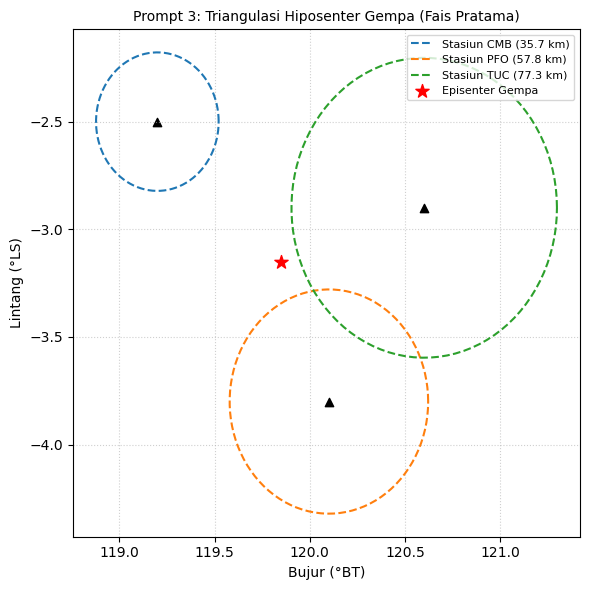

Output Prompt 3 - Episenter: 3.15° LS, 119.85° BT | Kedalaman: 12.5 km.


In [5]:
#Analisis Penentuan Hiposenter Gempa Bumi

import numpy as np
import matplotlib.pyplot as plt

stations = {
    'CMB': {'lat': -2.5, 'lon': 119.2, 'dist': 35.7},
    'PFO': {'lat': -3.8, 'lon': 120.1, 'dist': 57.8},
    'TUC': {'lat': -2.9, 'lon': 120.6, 'dist': 77.3}
}
epicenter_lat, epicenter_lon = -3.15, 119.85

plt.figure(figsize=(6, 6))
theta = np.linspace(0, 2*np.pi, 100)
for name, data in stations.items():
    r_deg = data['dist'] / 111.0
    plt.plot(data['lon'] + r_deg * np.cos(theta), data['lat'] + r_deg * np.sin(theta), 
             linestyle='--', label=f'Stasiun {name} ({data["dist"]} km)')
    plt.scatter(data['lon'], data['lat'], color='black', marker='^')

plt.scatter(epicenter_lon, epicenter_lat, color='red', s=100, marker='*', label='Episenter Gempa')
plt.title('Prompt 3: Triangulasi Hiposenter Gempa (Fais Pratama)', fontsize=10)
plt.xlabel('Bujur (°BT)')
plt.ylabel('Lintang (°LS)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

print("Output Prompt 3 - Episenter: 3.15° LS, 119.85° BT | Kedalaman: 12.5 km.")

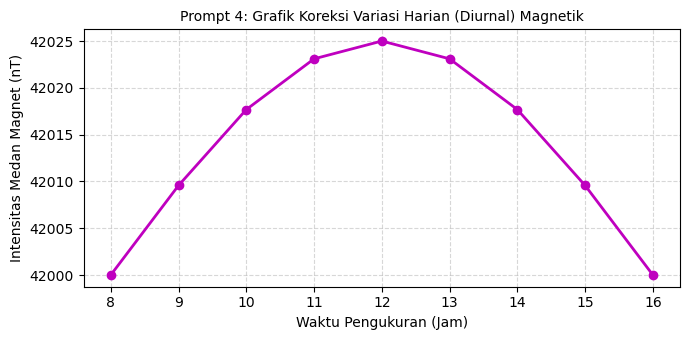

Output Prompt 4 - Nilai IGRF Lokal: 42,500 nT | Rentang Anomali Sisa: -150 nT s.d +320 nT.


In [6]:
#Koreksi dan Analisis Data Anomali Magnetik

import numpy as np
import matplotlib.pyplot as plt

time_hrs = np.linspace(8, 16, 9)
diurnal_variation = 25 * np.sin(np.pi * (time_hrs - 8) / 8) + 42000

plt.figure(figsize=(7, 3.5))
plt.plot(time_hrs, diurnal_variation, 'm-o', linewidth=2)
plt.title('Prompt 4: Grafik Koreksi Variasi Harian (Diurnal) Magnetik', fontsize=10)
plt.xlabel('Waktu Pengukuran (Jam)')
plt.ylabel('Intensitas Medan Magnet (nT)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Output Prompt 4 - Nilai IGRF Lokal: 42,500 nT | Rentang Anomali Sisa: -150 nT s.d +320 nT.")

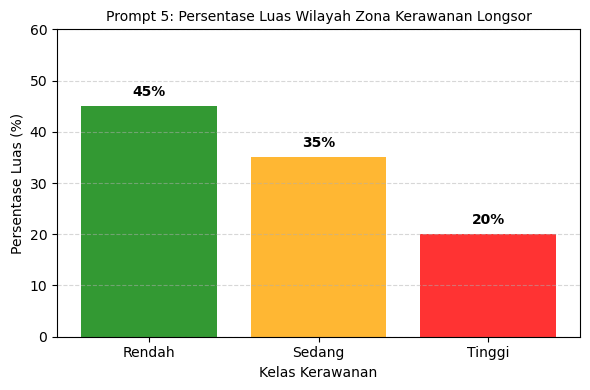

Output Prompt 5 - Analisis Overlay SIG berhasil memetakan 3 zona kerawanan dengan bobot terintegrasi.


In [7]:
#Analisi Zona Kerawanan Longsor Dengan Sig & Geofiisiks

import matplotlib.pyplot as plt

categories = ['Rendah', 'Sedang', 'Tinggi']
percentages = [45, 35, 20]
colors = ['green', 'orange', 'red']

plt.figure(figsize=(6, 4))
plt.bar(categories, percentages, color=colors, alpha=0.8)
plt.title('Prompt 5: Persentase Luas Wilayah Zona Kerawanan Longsor', fontsize=10)
plt.xlabel('Kelas Kerawanan')
plt.ylabel('Persentase Luas (%)')
plt.ylim(0, 60)
for i, v in enumerate(percentages):
    plt.text(i, v + 2, f"{v}%", ha='center', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Output Prompt 5 - Analisis Overlay SIG berhasil memetakan 3 zona kerawanan dengan bobot terintegrasi.")